# NOTEBOOK : 01_team_player_clustering.ipynb
# ROLE     : Segment Premier League teams and players into tactical profiles using K-Means (Elbow + Silhouette), DBSCAN, and Hierarchical Clustering (Chapter 4).
# INPUT    : ../../data/processed/clean_matches.csv, ../../data/processed/player_gw.csv, ../artifacts/metrics.json
# OUTPUT   : ../artifacts/models/clustering_model.joblib, ../../data/processed/team_clusters.csv, ../../data/processed/player_clusters.csv, ../reports/figures/*.png

In [1]:
from pathlib import Path
import json
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN, AgglomerativeClustering
from sklearn.metrics import silhouette_score

RANDOM_STATE = 42
K_RANGE = list(range(2, 9))
OPTIMAL_K_TEAMS = 4
OPTIMAL_K_PLAYERS = 4

PROCESSED_DIR = Path("../../data/processed")
ARTIFACTS_DIR = Path("../artifacts")
MODELS_DIR = ARTIFACTS_DIR / "models"
FIGURES_DIR = Path("../reports/figures")

MODELS_DIR.mkdir(parents=True, exist_ok=True)
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

TEAM_FEATURES = [
    "goals_for_pg",
    "goals_against_pg",
    "shots_pg",
    "shots_on_target_pg",
    "home_ppg",
    "away_ppg",
]

PLAYER_FEATURES = [
    "goals_p90",
    "assists_p90",
    "points_p90",
    "bps_p90",
    "ict_p90",
    "clean_sheets_p90",
]

print("Configuration loaded.")

Configuration loaded.


In [2]:
matches_df = pd.read_csv(PROCESSED_DIR / "clean_matches.csv")
played_df = matches_df[matches_df["Full_Time_Result"].notna()].copy()

def build_team_stats(df):
    """Aggregate per-game attacking, defensive, and home/away points for every team."""
    records = []
    all_teams = sorted(set(df["Home_Team"]) | set(df["Away_Team"]))

    for team in all_teams:
        home_m = df[df["Home_Team"] == team]
        away_m = df[df["Away_Team"] == team]
        total_games = len(home_m) + len(away_m)

        gf = home_m["Full_Time_Home_Goals"].sum() + away_m["Full_Time_Away_Goals"].sum()
        ga = home_m["Full_Time_Away_Goals"].sum() + away_m["Full_Time_Home_Goals"].sum()
        shots = home_m["Home_Shots"].sum() + away_m["Away_Shots"].sum()
        sot = home_m["Home_Shots_On_Target"].sum() + away_m["Away_Shots_On_Target"].sum()

        home_pts = (home_m["Full_Time_Result"] == "H").sum() * 3 + (home_m["Full_Time_Result"] == "D").sum()
        away_pts = (away_m["Full_Time_Result"] == "A").sum() * 3 + (away_m["Full_Time_Result"] == "D").sum()

        records.append({
            "team_name": team,
            "matches_played": total_games,
            "goals_for_pg": round(gf / total_games, 3),
            "goals_against_pg": round(ga / total_games, 3),
            "shots_pg": round(shots / total_games, 3),
            "shots_on_target_pg": round(sot / total_games, 3),
            "home_ppg": round(home_pts / len(home_m), 3) if len(home_m) > 0 else 0.0,
            "away_ppg": round(away_pts / len(away_m), 3) if len(away_m) > 0 else 0.0,
        })
    return pd.DataFrame(records)

team_stats = build_team_stats(played_df)
print(f"Aggregated stats for {len(team_stats)} teams.")
display(team_stats.head())

Aggregated stats for 30 teams.


,team_name,matches_played,goals_for_pg,goals_against_pg,shots_pg,shots_on_target_pg,home_ppg,away_ppg
0,Arsenal,235,1.898,0.957,14.821,5.043,2.188,1.898
1,Aston Villa,235,1.511,1.353,12.596,4.477,1.752,1.381
2,Bournemouth,159,1.358,1.579,13.258,4.616,1.412,1.177
3,Brentford,197,1.503,1.442,11.487,4.305,1.545,1.122
4,Brighton,235,1.489,1.340,14.060,4.864,1.542,1.282


K=2 | Inertia=  79.41 | Silhouette=0.4408
K=3 | Inertia=  40.10 | Silhouette=0.4477
K=4 | Inertia=  23.96 | Silhouette=0.4494
K=5 | Inertia=  20.20 | Silhouette=0.3870
K=6 | Inertia=  16.48 | Silhouette=0.3712
K=7 | Inertia=  14.35 | Silhouette=0.3350
K=8 | Inertia=  12.28 | Silhouette=0.3301


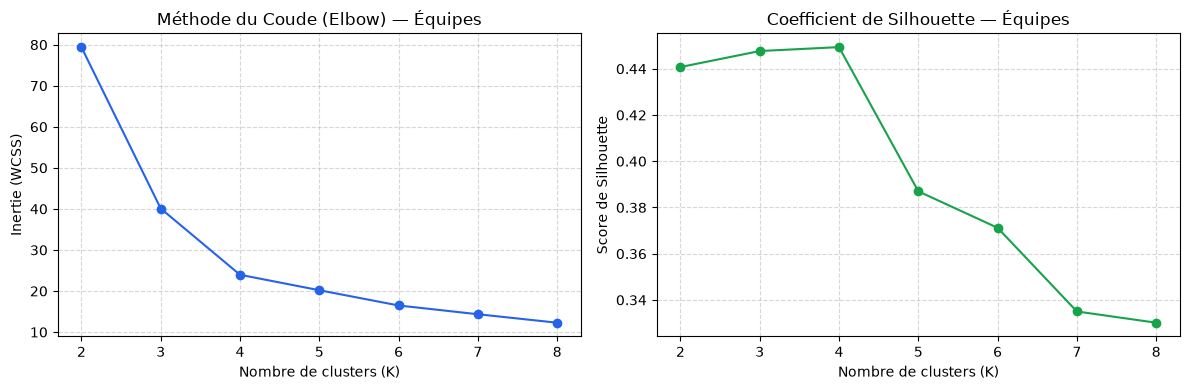

In [3]:
team_scaler = StandardScaler()
X_team_scaled = team_scaler.fit_transform(team_stats[TEAM_FEATURES])

def evaluate_kmeans_range(X_scaled, k_list):
    """Run K-Means for each K and return inertia and silhouette lists."""
    inertias = []
    silhouettes = []
    for k in k_list:
        km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE)
        labels = km.fit_predict(X_scaled)
        inertias.append(float(km.inertia_))
        silhouettes.append(float(silhouette_score(X_scaled, labels)))
    return inertias, silhouettes

team_inertias, team_silhouettes = evaluate_kmeans_range(X_team_scaled, K_RANGE)

for k, iner, sil in zip(K_RANGE, team_inertias, team_silhouettes):
    print(f"K={k} | Inertia={iner:7.2f} | Silhouette={sil:.4f}")

# Plot Elbow & Silhouette curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(K_RANGE, team_inertias, marker="o", color="#2563eb")
axes[0].set_title("Méthode du Coude (Elbow) — Équipes")
axes[0].set_xlabel("Nombre de clusters (K)")
axes[0].set_ylabel("Inertie (WCSS)")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(K_RANGE, team_silhouettes, marker="o", color="#16a34a")
axes[1].set_title("Coefficient de Silhouette — Équipes")
axes[1].set_xlabel("Nombre de clusters (K)")
axes[1].set_ylabel("Score de Silhouette")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "clustering_team_elbow_silhouette.png", dpi=150)
plt.show()

In [4]:
team_kmeans = KMeans(n_clusters=OPTIMAL_K_TEAMS, n_init=10, random_state=RANDOM_STATE)
team_stats["cluster_id"] = team_kmeans.fit_predict(X_team_scaled)
team_km_silhouette = float(silhouette_score(X_team_scaled, team_stats["cluster_id"]))

# Inspect centroids in original scale
centroids = team_stats.groupby("cluster_id")[TEAM_FEATURES].mean()
centroids["overall_strength"] = centroids["home_ppg"] + centroids["away_ppg"] + (centroids["goals_for_pg"] - centroids["goals_against_pg"])
ordered_ids = centroids.sort_values("overall_strength", ascending=False).index.tolist()

# Assign deterministic French tactical profile labels based on strength rank
PROFILE_NAMES_4 = [
    "Attaque dominante",
    "Équipe équilibrée",
    "Bloc défensif",
    "Équipe en difficulté",
]
PROFILE_NAMES_3 = [
    "Attaque dominante",
    "Équipe équilibrée",
    "Bloc défensif",
]
label_pool = PROFILE_NAMES_4 if OPTIMAL_K_TEAMS == 4 else PROFILE_NAMES_3
team_label_map = {cid: label_pool[idx] for idx, cid in enumerate(ordered_ids)}

team_stats["cluster_label"] = team_stats["cluster_id"].map(team_label_map)

print(f"Final Team K-Means (K={OPTIMAL_K_TEAMS}) Silhouette Score: {team_km_silhouette:.4f}\n")
display(centroids.drop(columns=["overall_strength"]).assign(profile=[team_label_map[i] for i in centroids.index]))

for cid in ordered_ids:
    members = team_stats[team_stats["cluster_id"] == cid]["team_name"].tolist()
    print(f"\n[{cid}] {team_label_map[cid]} ({len(members)} équipes): {', '.join(members)}")

Final Team K-Means (K=4) Silhouette Score: 0.4494



,goals_for_pg,goals_against_pg,shots_pg,shots_on_target_pg,home_ppg,away_ppg,profile
cluster_id,,,,,,,
0,1.244818,1.463364,11.513636,3.915273,1.401000,1.056455,Bloc défensif
1,0.930556,2.053111,10.151667,3.325333,0.742556,0.636556,Équipe en difficulté
2,2.081000,0.984333,16.280667,5.693667,2.272333,1.912667,Attaque dominante
3,1.552000,1.387857,13.579286,4.832714,1.664571,1.332571,Équipe équilibrée



[2] Attaque dominante (3 équipes): Arsenal, Liverpool, Man City

[3] Équipe équilibrée (7 équipes): Aston Villa, Bournemouth, Brighton, Chelsea, Man United, Newcastle, Tottenham

[0] Bloc défensif (11 équipes): Brentford, Crystal Palace, Everton, Fulham, Hull, Leeds, Leicester, Nottingham Forest, Sunderland, West Ham, Wolves

[1] Équipe en difficulté (9 équipes): Burnley, Coventry, Ipswich, Luton, Norwich, Sheffield United, Southampton, Watford, West Brom


Silhouette K-Means      : 0.4494
Silhouette Hiérarchique : 0.4496
DBSCAN clusters trouvés : 1 | Silhouette (hors bruit): None
Équipes atypiques (DBSCAN = -1): ['Arsenal', 'Liverpool', 'Man City']


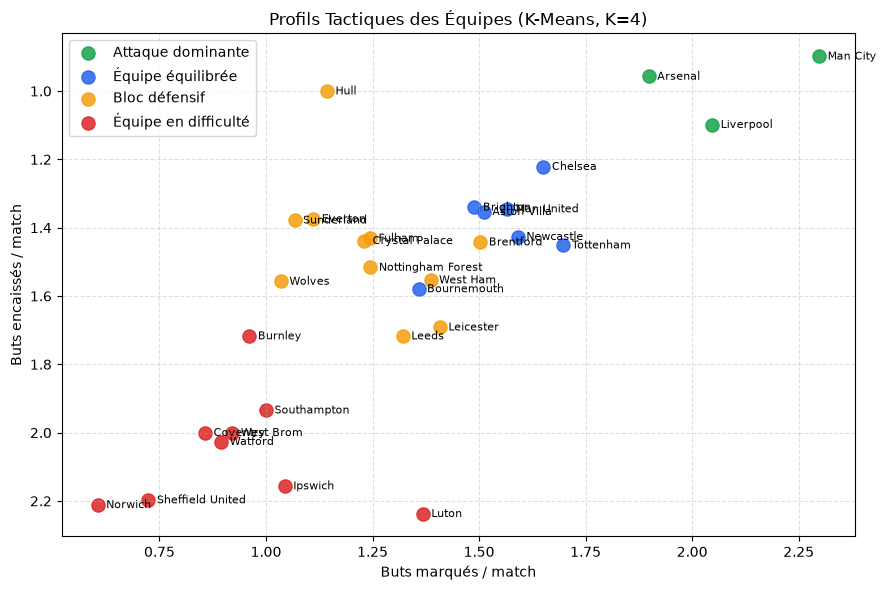

In [5]:
# 1. Hierarchical Clustering (Agglomerative)
team_agg = AgglomerativeClustering(n_clusters=OPTIMAL_K_TEAMS, linkage="ward")
team_stats["agg_cluster"] = team_agg.fit_predict(X_team_scaled)
team_agg_silhouette = float(silhouette_score(X_team_scaled, team_stats["agg_cluster"]))

# 2. DBSCAN (spot atypical/outlier teams)
team_dbscan = DBSCAN(eps=1.6, min_samples=3)
team_stats["dbscan_cluster"] = team_dbscan.fit_predict(X_team_scaled)
n_db_clusters = len(set(team_stats["dbscan_cluster"]) - {-1})
outliers = team_stats[team_stats["dbscan_cluster"] == -1]["team_name"].tolist()

if n_db_clusters >= 2:
    mask_valid = team_stats["dbscan_cluster"] != -1
    team_db_silhouette = float(silhouette_score(X_team_scaled[mask_valid], team_stats.loc[mask_valid, "dbscan_cluster"]))
else:
    team_db_silhouette = None

print(f"Silhouette K-Means      : {team_km_silhouette:.4f}")
print(f"Silhouette Hiérarchique : {team_agg_silhouette:.4f}")
print(f"DBSCAN clusters trouvés : {n_db_clusters} | Silhouette (hors bruit): {team_db_silhouette}")
print(f"Équipes atypiques (DBSCAN = -1): {outliers}")

# 2D Tactical Scatter Plot (Goals Scored vs Goals Conceded)
plt.figure(figsize=(9, 6))
colors = ["#16a34a", "#2563eb", "#f59e0b", "#dc2626"]
for idx, cid in enumerate(ordered_ids):
    sub = team_stats[team_stats["cluster_id"] == cid]
    plt.scatter(sub["goals_for_pg"], sub["goals_against_pg"], s=90, color=colors[idx], label=team_label_map[cid], alpha=0.85)
    for _, row in sub.iterrows():
        plt.annotate(row["team_name"], (row["goals_for_pg"] + 0.02, row["goals_against_pg"] + 0.01), fontsize=8)

plt.xlabel("Buts marqués / match")
plt.ylabel("Buts encaissés / match")
plt.title(f"Profils Tactiques des Équipes (K-Means, K={OPTIMAL_K_TEAMS})")
plt.gca().invert_yaxis()  # Lower goals conceded is better (top-right = dominant)
plt.legend()
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "clustering_team_profiles.png", dpi=150)
plt.show()

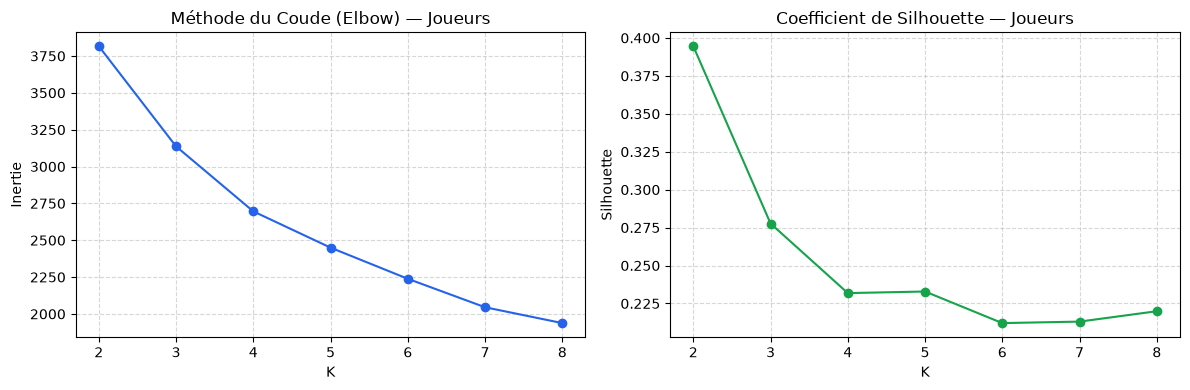

Player K-Means Silhouette      : 0.2318
Player Hiérarchique Silhouette : 0.1981
Player DBSCAN outliers (-1)    : 43 / 1069


,goals_p90,assists_p90,points_p90,bps_p90,ict_p90,clean_sheets_p90,profile
cluster_id,,,,,,,
0,0.034921,0.043534,2.666111,12.709623,3.211911,0.136562,Profil défensif / Soutien
1,0.455438,0.263378,6.397765,22.601840,8.533603,0.305569,Star offensive
2,0.052226,0.064254,3.668287,16.434773,3.614010,0.316570,Titulaire régulier
3,0.210982,0.191073,4.630481,16.602136,6.183118,0.264707,Créateur influent


In [6]:
gw_df = pd.read_csv(PROCESSED_DIR / "player_gw.csv", low_memory=False)

# Aggregate per-90 stats across all seasons for players with >= 450 minutes
p_agg = gw_df.groupby("player_key", as_index=False).agg(
    name=("name", "last"),
    position=("position", "last"),
    team=("team", "last"),
    total_minutes=("minutes", "sum"),
    goals=("goals_scored", "sum"),
    assists=("assists", "sum"),
    points=("total_points", "sum"),
    bps=("bps", "sum"),
    ict=("ict_index", "sum"),
    clean_sheets=("clean_sheets", "sum"),
)

player_stats = p_agg[p_agg["total_minutes"] >= 450].copy().reset_index(drop=True)
mins_90 = player_stats["total_minutes"] / 90.0

player_stats["goals_p90"] = player_stats["goals"] / mins_90
player_stats["assists_p90"] = player_stats["assists"] / mins_90
player_stats["points_p90"] = player_stats["points"] / mins_90
player_stats["bps_p90"] = player_stats["bps"] / mins_90
player_stats["ict_p90"] = player_stats["ict"] / mins_90
player_stats["clean_sheets_p90"] = player_stats["clean_sheets"] / mins_90

player_scaler = StandardScaler()
X_player_scaled = player_scaler.fit_transform(player_stats[PLAYER_FEATURES])

p_inertias, p_silhouettes = evaluate_kmeans_range(X_player_scaled, K_RANGE)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(K_RANGE, p_inertias, marker="o", color="#2563eb")
axes[0].set_title("Méthode du Coude (Elbow) — Joueurs")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertie")
axes[0].grid(True, linestyle="--", alpha=0.5)

axes[1].plot(K_RANGE, p_silhouettes, marker="o", color="#16a34a")
axes[1].set_title("Coefficient de Silhouette — Joueurs")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Silhouette")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "clustering_player_elbow_silhouette.png", dpi=150)
plt.show()

# Fit final Player K-Means
player_kmeans = KMeans(n_clusters=OPTIMAL_K_PLAYERS, n_init=10, random_state=RANDOM_STATE)
player_stats["cluster_id"] = player_kmeans.fit_predict(X_player_scaled)
player_km_silhouette = float(silhouette_score(X_player_scaled, player_stats["cluster_id"]))

# Compare with Hierarchical & DBSCAN
player_agg_model = AgglomerativeClustering(n_clusters=OPTIMAL_K_PLAYERS, linkage="ward")
player_agg_silhouette = float(silhouette_score(X_player_scaled, player_agg_model.fit_predict(X_player_scaled)))

player_db = DBSCAN(eps=1.5, min_samples=10).fit_predict(X_player_scaled)
player_outliers_count = int((player_db == -1).sum())

# Deterministic French labels ranked by points_p90
p_centroids = player_stats.groupby("cluster_id")[PLAYER_FEATURES].mean()
p_ordered = p_centroids.sort_values("points_p90", ascending=False).index.tolist()
PLAYER_LABELS = [
    "Star offensive",
    "Créateur influent",
    "Titulaire régulier",
    "Profil défensif / Soutien",
]
player_label_map = {cid: PLAYER_LABELS[idx] for idx, cid in enumerate(p_ordered)}
player_stats["cluster_label"] = player_stats["cluster_id"].map(player_label_map)

print(f"Player K-Means Silhouette      : {player_km_silhouette:.4f}")
print(f"Player Hiérarchique Silhouette : {player_agg_silhouette:.4f}")
print(f"Player DBSCAN outliers (-1)    : {player_outliers_count} / {len(player_stats)}")
display(p_centroids.assign(profile=[player_label_map[i] for i in p_centroids.index]))

In [7]:
# 1. Export CSVs
team_clusters_path = PROCESSED_DIR / "team_clusters.csv"
player_clusters_path = PROCESSED_DIR / "player_clusters.csv"

team_stats.to_csv(team_clusters_path, index=False)
player_stats.to_csv(player_clusters_path, index=False)
print(f"[SAVED] {team_clusters_path} ({len(team_stats)} teams)")
print(f"[SAVED] {player_clusters_path} ({len(player_stats)} players)")

# 2. Save clustering_model.joblib bundle
clustering_bundle = {
    "team_features": TEAM_FEATURES,
    "team_scaler": team_scaler,
    "team_kmeans": team_kmeans,
    "team_label_map": team_label_map,
    "player_features": PLAYER_FEATURES,
    "player_scaler": player_scaler,
    "player_kmeans": player_kmeans,
    "player_label_map": player_label_map,
}
model_path = MODELS_DIR / "clustering_model.joblib"
joblib.dump(clustering_bundle, model_path)
print(f"[SAVED] {model_path}")

# 3. Update metrics.json with clustering metrics
metrics_path = ARTIFACTS_DIR / "metrics.json"
if metrics_path.exists():
    with open(metrics_path, "r", encoding="utf-8") as f:
        metrics_data = json.load(f)
else:
    metrics_data = {}

metrics_data["clustering"] = {
    "teams": {
        "optimal_k": OPTIMAL_K_TEAMS,
        "kmeans_silhouette": round(team_km_silhouette, 4),
        "hierarchical_silhouette": round(team_agg_silhouette, 4),
        "dbscan_clusters": n_db_clusters,
        "dbscan_outliers": outliers,
        "elbow_curve": {str(k): round(v, 2) for k, v in zip(K_RANGE, team_inertias)},
        "silhouette_curve": {str(k): round(v, 4) for k, v in zip(K_RANGE, team_silhouettes)},
        "profiles": {str(k): v for k, v in team_label_map.items()},
    },
    "players": {
        "optimal_k": OPTIMAL_K_PLAYERS,
        "n_players_clustered": int(len(player_stats)),
        "kmeans_silhouette": round(player_km_silhouette, 4),
        "hierarchical_silhouette": round(player_agg_silhouette, 4),
        "dbscan_outliers_count": player_outliers_count,
        "profiles": {str(k): v for k, v in player_label_map.items()},
    },
}

with open(metrics_path, "w", encoding="utf-8") as f:
    json.dump(metrics_data, f, indent=2, ensure_ascii=False)
print(f"[UPDATED] {metrics_path} with Chapter 4 clustering metrics.")

[SAVED] ..\..\data\processed\team_clusters.csv (30 teams)
[SAVED] ..\..\data\processed\player_clusters.csv (1069 players)
[SAVED] ..\artifacts\models\clustering_model.joblib
[UPDATED] ..\artifacts\metrics.json with Chapter 4 clustering metrics.
